# План-факт анализ продаж и ABC/XYZ-анализ по VALTEC

**Цель:** Сопоставить планы продаж отдела продаж (в маржинальной прибыли и в количестве) с фактическими данными по всему датасету и по подмножеству VALTEC; рассчитать метрики ошибок (MAE, RMSE, MAPE, PE) по кварталам 2023–2024; провести ABC/XYZ-анализ отдельно для VALTEC.

**Вход:**
- `df_final_себестоимость_выручка_ABC_XYZ_кол.xlsx` — основной датасет по движению (деньги + количество).
- `df_final полный движение с категориями.xlsx` — датасет по количеству.
- `артикул поставщика и наш код с 2021 по 2025.xlsx` — справочник артикулов.
- `Валтек.xlsx` — список кодов VALTEC.
- `План продаж МП.xlsx` — план/факт отдела продаж по маржинальной прибыли (2021–2024).
- `240404_Металлпласт_2024.xlsx` и `230317_Металлпласт_2023.xlsx` — годовые планы продаж VALTEC по кварталам.

**Основные шаги:**
1. Расчёт маржинальной прибыли (МП = Выручка − Расход) и сопоставление с планом отдела продаж (сглаживание выбросов).
2. Расчёт ошибок плана: MAE, RMSE, MAPE, средняя процентная ошибка (PE).
3. Выделение подмножества VALTEC по общим артикулам во всех источниках (основной датасет + планы 2023 и 2024).
4. Сравнение факта по количеству (в штуках) с планами по кварталам за 2023 и 2024 годы; построение графиков и диаграмм.
5. Расчёт MAE, RMSE, MAPE, PE по кварталам и по году в целом для 2023 и 2024.
6. ABC-анализ по кумулятивной доле выручки и XYZ-анализ по коэффициенту вариации расхода в штуках для VALTEC.
7. Построение матрицы ABC × XYZ и визуализация результатов.

**Навыки:** pandas, numpy, seaborn, matplotlib, ABC/XYZ-анализ, метрики ошибок прогноза.

In [690]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.ticker as mticker
import matplotlib.ticker as ticker
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

In [2]:
ddd = pd.read_excel('df_final_себестоимость_выручка_ABC_XYZ_кол.xlsx')

In [3]:
ddd

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,Год,ABC_категория,ABC_2024,XYZ_2024,XYZ_all
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,20379.08,48774.81,56835.83,25834.47,75469.85,2,2021,A,A,X,X
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.00,86530.76,86530.76,0.00,106442.65,2,2022,A,A,X,X
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2023-08-01,0.00,30935.01,30935.01,0.00,38734.71,2,2023,A,A,X,X
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.00,59738.32,59738.32,0.00,90496.00,2,2024,A,A,X,X
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-04-01,61571.85,7941.28,46342.08,23171.05,57718.98,2,2021,A,A,X,X
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723430,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2021-01-01,211.72,175.00,64.45,322.27,89.88,1,2021,C,C,Y,X
723431,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2022-01-01,293.31,0.00,0.00,293.31,0.00,1,2022,C,C,Y,X
723432,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2023-01-01,244.84,0.00,104.93,139.91,172.06,1,2023,C,C,Y,X
723433,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,2024-01-01,270.70,0.00,0.00,270.70,0.00,1,2024,C,C,Y,X


In [5]:
ddd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 723435 entries, 0 to 723434
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Код                723435 non-null  object        
 1   Номенклатура       723435 non-null  object        
 2   Ед_изм             723435 non-null  object        
 3   Дата               723435 non-null  datetime64[ns]
 4   Начальный_остаток  723435 non-null  float64       
 5   Приход             723435 non-null  float64       
 6   Расход             723435 non-null  float64       
 7   Конечный_остаток   723435 non-null  float64       
 8   Выручка            723435 non-null  float64       
 9   Категория          723435 non-null  int64         
 10  Год                723435 non-null  int64         
 11  ABC_категория      723435 non-null  object        
 12  ABC_2024           723435 non-null  object        
 13  XYZ_2024           723435 non-null  object  

In [6]:
df_final = ddd.copy()

In [8]:
df_final.columns

Index(['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток', 'Приход',
       'Расход', 'Конечный_остаток', 'Выручка', 'Категория', 'Год',
       'ABC_категория', 'ABC_2024', 'XYZ_2024', 'XYZ_all'],
      dtype='object')

In [10]:
# Для каждой катгории итоговые дф
df_sklad_itog = df_final[df_final['Категория'] == 1].groupby('Дата')[['Начальный_остаток', 'Приход', 'Расход', 'Конечный_остаток', 'Выручка']].sum().reset_index()
df_zakaz_itog = df_final[df_final['Категория'] == 2].groupby('Дата')[['Начальный_остаток', 'Приход', 'Расход', 'Конечный_остаток', 'Выручка']].sum().reset_index()
df_itog = df_final.groupby('Дата')[['Начальный_остаток', 'Приход', 'Расход', 'Конечный_остаток', 'Выручка']].sum().reset_index()

In [11]:
df_sklad_itog['Год'] = df_sklad_itog['Дата'].dt.year
df_zakaz_itog['Год'] = df_zakaz_itog['Дата'].dt.year
df_itog['Год'] = df_itog['Дата'].dt.year

df_sklad_itog['Месяц'] = df_sklad_itog['Дата'].dt.month
df_zakaz_itog['Месяц'] = df_zakaz_itog['Дата'].dt.month
df_itog['Месяц'] = df_itog['Дата'].dt.month

In [12]:
df_all_itog_year = df_final.groupby('Год')[['Начальный_остаток', 'Приход', 'Расход', 'Конечный_остаток', 'Выручка']].sum().reset_index()

In [13]:
df_all_itog_year = df_all_itog_year[df_all_itog_year['Год'] != 2025]

### Проверка на совпадение

In [25]:
df_final[df_final['Номенклатура'].str.contains('Соединитель пресс', case=False, na=False)]

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,Год,ABC_категория,ABC_2024,XYZ_2024,XYZ_all


# АРТИКУЛЫ добавление в основной дф

In [55]:
art = pd.read_excel('артикул поставщика и наш код с 2021 по 2025.xlsx')

In [56]:
art = art.iloc[7:, :5]
art.columns = art.iloc[0]
art = art[3:-1].reset_index(drop=True)
art = art.drop(art.columns[[2, 3]], axis=1)
art.columns = ['Артикул', 'Код', 'Номенклатура']

In [106]:
art.isna().sum()

Артикул         2031
Код                0
Номенклатура       0
dtype: int64

In [68]:
# Объединяем по 'Код', добавляем только 'Артикул'
df_final = df_final.merge(
    art[['Код', 'Артикул']],
    on='Код',
    how='left'  # оставляем только строки из final_df
)

### Создание столбца МП (маржинальная прибыль): Выручка - Расход

In [186]:
df_itog['МП'] = df_itog['Выручка'] - df_itog['Расход']

In [187]:
df_itog

,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Год,Месяц,МП
0,2021-01-01,36543313.51,25424147.60,22675212.34,39195854.45,26373589.12,2021,1,3698376.78
1,2021-02-01,39195854.45,22958618.30,26523382.41,35945562.09,32533726.88,2021,2,6010344.47
2,2021-03-01,35945562.09,24032461.89,29476847.35,30152818.65,36013781.32,2021,3,6536933.97
3,2021-04-01,30152818.65,37997364.33,34245705.59,33933381.80,41116870.43,2021,4,6871164.84
4,2021-05-01,33933381.80,30698501.23,27887905.76,36105411.78,33540964.03,2021,5,5653058.27
5,2021-06-01,36105411.78,32360699.54,32757974.74,35141370.86,39804751.28,2021,6,7046776.54
6,2021-07-01,35141370.86,32012742.42,31432335.75,35160895.29,39204360.34,2021,7,7772024.59
7,2021-08-01,35160895.29,28576321.33,31620487.09,31951469.80,39343005.08,2021,8,7722517.99
8,2021-09-01,31951469.80,31101394.77,33153508.23,30032823.40,40884544.41,2021,9,7731036.18
9,2021-10-01,30032823.40,39432145.98,36460085.19,32458184.20,45858075.56,2021,10,9397990.37


# ПЛАН ПРОДАЖ отдела продаж план и факт в МП (Елена Сергеевна)

In [731]:
plan_mp = pd.read_excel('План продаж МП.xlsx')

In [732]:
plan_mp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Дата        60 non-null     datetime64[ns]
 1   План        60 non-null     int64         
 2   Факт        51 non-null     float64       
 3   ПЛАН скорр  51 non-null     float64       
dtypes: datetime64[ns](1), float64(2), int64(1)
memory usage: 2.0 KB


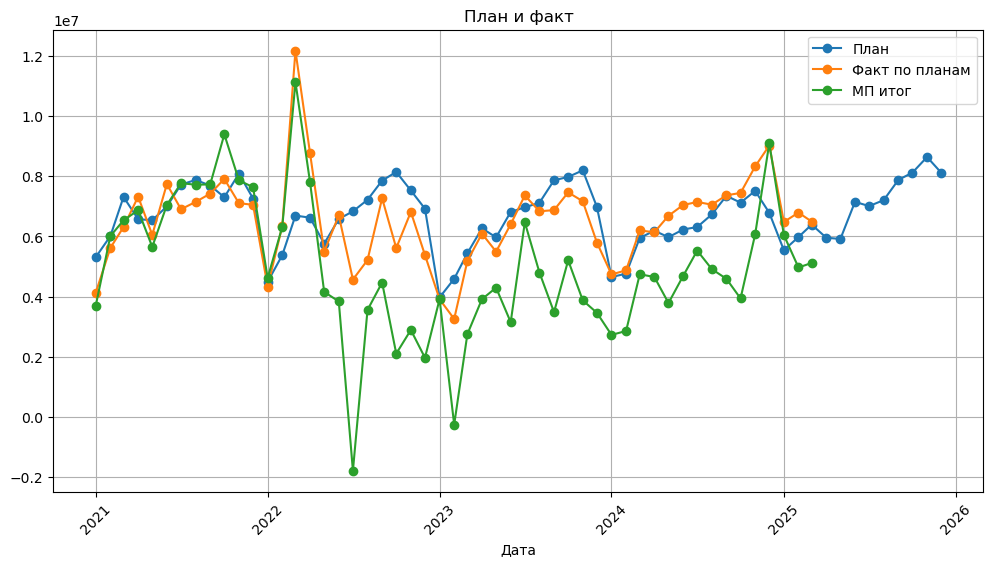

In [733]:
plt.figure(figsize=(12, 6))
# Рисуем линии
plt.plot(plan_mp['Дата'], plan_mp['План'], label='План', marker='o')
plt.plot(plan_mp['Дата'], plan_mp['Факт'], label='Факт по планам', marker='o')
plt.plot(df_itog['Дата'], df_itog['МП'], label='МП итог', marker='o')
#plt.plot(df_itog['Дата'], df_itog['Выручка'], label='Выручка', marker='o')

# Добавляем подписи
plt.xlabel('Дата')
#plt.ylabel('Расход')
plt.title('План и факт')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

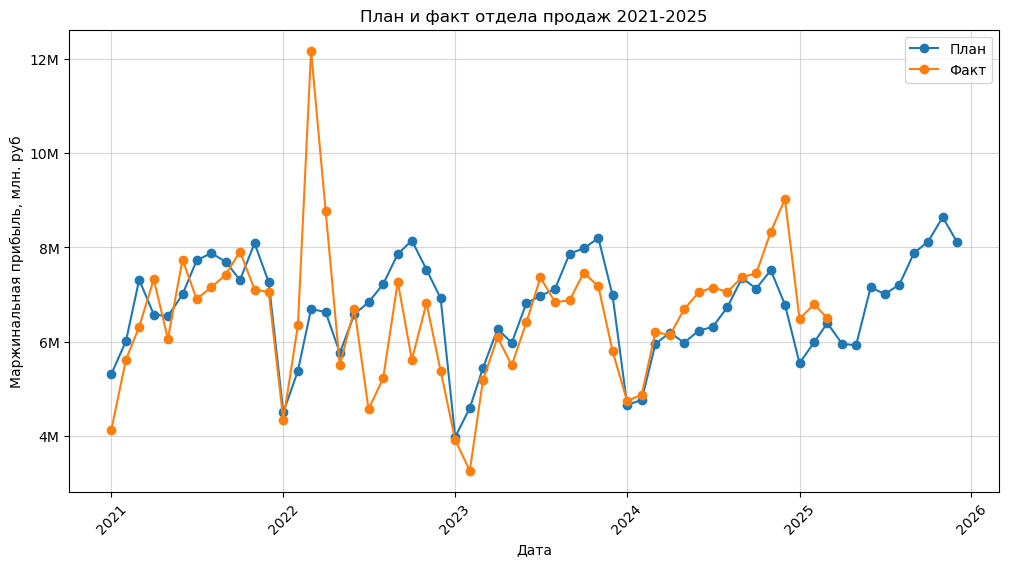

In [734]:
plt.figure(figsize=(12, 6))
# Рисуем линии
plt.plot(plan_mp['Дата'], plan_mp['План'], label='План', marker='o')
plt.plot(plan_mp['Дата'], plan_mp['Факт'], label='Факт', marker='o')
#plt.plot(df_itog['Дата'], df_itog['МП'], label='МП итог', marker='o')
#plt.plot(df_itog['Дата'], df_itog['Выручка'], label='Выручка', marker='o')

# Добавляем подписи
plt.xlabel('Дата')
plt.ylabel('Маржинальная прибыль, млн. руб')
plt.title('План и факт отдела продаж 2021-2025')
plt.legend()
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x*1e-6)}M' if x >= 1e6 else f'{x*1e-6:.1f}M'))
plt.grid(alpha=0.5)
plt.xticks(rotation=45)
plt.show()

In [712]:
plan_mp['Год'] = plan_mp['Дата'].dt.year
plan_mp = plan_mp[plan_mp['Год'] != 2025]

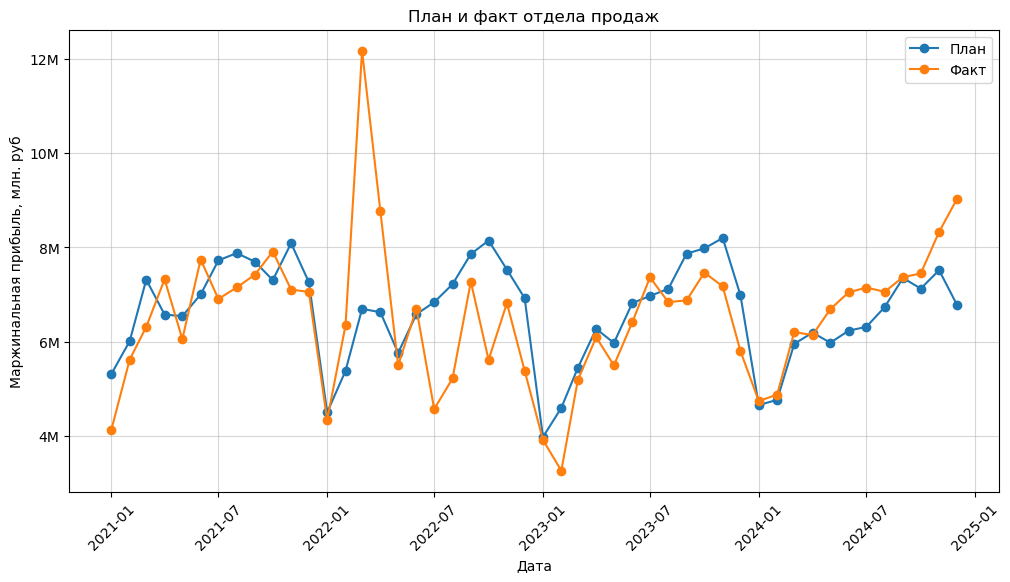

In [715]:
plt.figure(figsize=(12, 6))
# Рисуем линии
plt.plot(plan_mp['Дата'], plan_mp['План'], label='План', marker='o')
plt.plot(plan_mp['Дата'], plan_mp['Факт'], label='Факт', marker='o')
#plt.plot(df_itog['Дата'], df_itog['МП'], label='МП итог', marker='o')
#plt.plot(df_itog['Дата'], df_itog['Выручка'], label='Выручка', marker='o')

# Добавляем подписи
plt.xlabel('Дата')
plt.ylabel('Маржинальная прибыль, млн. руб')
plt.title('План и факт отдела продаж')
plt.legend()
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x*1e-6)}M' if x >= 1e6 else f'{x*1e-6:.1f}M'))
plt.grid(alpha=0.5)
plt.xticks(rotation=45)
plt.show()

In [723]:
plan_mp_1 = plan_mp.copy()

In [727]:
plan_mp

,Дата,План,Факт,ПЛАН скорр,Год
0,2021-01-01,5310000,4126000.0,5310000.0,2021
1,2021-02-01,6010000,5617500.0,6010000.0,2021
2,2021-03-01,7315000,6312000.0,7315000.0,2021
3,2021-04-01,6574000,7324000.0,6574000.0,2021
4,2021-05-01,6540000,6052100.0,6540000.0,2021
5,2021-06-01,7000000,7743770.0,7000000.0,2021
6,2021-07-01,7725000,6904800.0,7725000.0,2021
7,2021-08-01,7880000,7149000.0,7880000.0,2021
8,2021-09-01,7695000,7424000.0,7695000.0,2021
9,2021-10-01,7305000,7913700.0,7305000.0,2021


In [728]:
# Заменим выбросы на интерполированные значения 8767981.0  9026255.0
plan_mp_1['Факт'] = plan_mp_1['Факт'].replace([12181586.0], np.nan)  # Преобразуем выбросы в NaN
plan_mp_1['Факт'] = plan_mp_1['Факт'].replace([8767981.0], np.nan)
plan_mp_1['Факт'] = plan_mp_1['Факт'].replace([9026255.0], np.nan)
plan_mp_1['Факт'] = plan_mp_1['Факт'].interpolate()  # Интерполируем значения для NaN

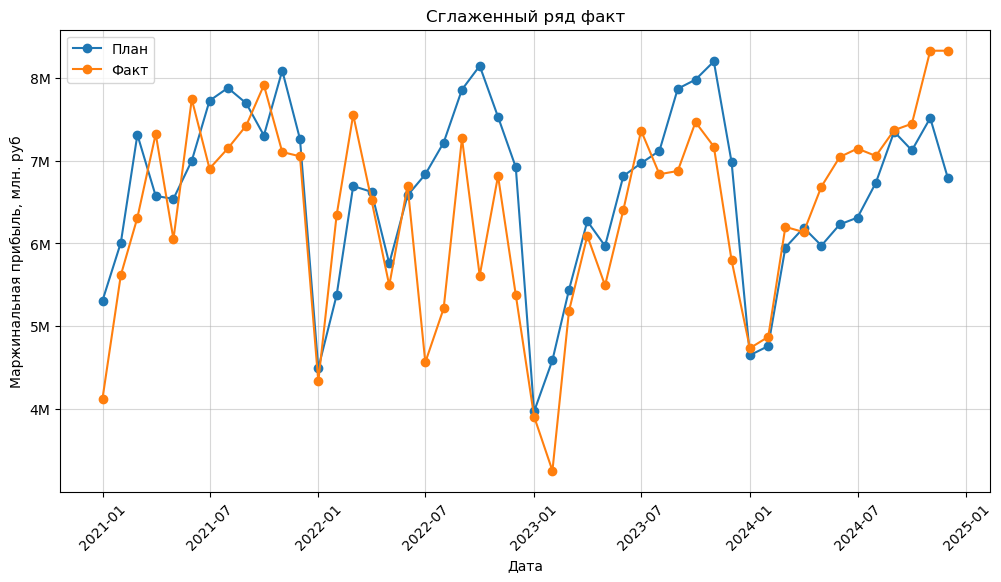

In [729]:
plt.figure(figsize=(12, 6))
# Рисуем линии
plt.plot(plan_mp_1['Дата'], plan_mp_1['План'], label='План', marker='o')
plt.plot(plan_mp_1['Дата'], plan_mp_1['Факт'], label='Факт', marker='o')
#plt.plot(df_itog['Дата'], df_itog['МП'], label='МП итог', marker='o')
#plt.plot(df_itog['Дата'], df_itog['Выручка'], label='Выручка', marker='o')

# Добавляем подписи
plt.xlabel('Дата')
plt.ylabel('Маржинальная прибыль, млн. руб')
plt.title('Сглаженный ряд факт')
plt.legend()
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x*1e-6)}M' if x >= 1e6 else f'{x*1e-6:.1f}M'))
plt.grid(alpha=0.5)
plt.xticks(rotation=45)
plt.show()

In [721]:
plan_mp.describe()

,Дата,План,Факт,ПЛАН скорр,Год
count,48,4.800000e+01,4.800000e+01,4.800000e+01,48.000000
mean,2022-12-16 05:00:00,6.635586e+06,6.527316e+06,6.592253e+06,2022.500000
min,2021-01-01 00:00:00,3.970000e+06,3.254213e+06,3.970000e+06,2021.000000
25%,2021-12-24 06:00:00,6.001164e+06,5.582943e+06,6.001164e+06,2021.750000
50%,2022-12-16 12:00:00,6.801440e+06,6.757667e+06,6.758500e+06,2022.500000
75%,2023-12-08 18:00:00,7.324000e+06,7.284607e+06,7.324000e+06,2023.250000
max,2024-12-01 00:00:00,8.200000e+06,1.218159e+07,8.146748e+06,2024.000000
std,NaN,1.047108e+06,1.500114e+06,1.008037e+06,1.129865


In [196]:
r = plan_mp['Факт'] - df_itog['МП']
r

0      427623.22
1     -392844.47
2     -224933.97
3      452835.16
4      399041.73
5      696993.46
6     -867224.59
7     -573517.99
8     -307036.18
9    -1484290.37
10    -759446.26
11    -587121.82
12    -284621.05
13      22588.66
14    1040782.26
15     964985.09
16    1339383.35
17    2862541.74
18    6361745.24
19    1660914.47
20    2805795.91
21    3513708.08
22    3928722.38
23    3418152.08
24      -3825.83
25    3518127.14
26    2436647.19
27    2179607.38
28    1200027.80
29    3260364.33
30     893980.45
31    2037579.22
32    3397202.03
33    2261821.68
34    3298605.51
35    2339107.85
36    2012417.18
37    2018264.49
38    1459966.17
39    1487608.89
40    2904427.65
41    2364281.66
42    1618401.92
43    2145442.32
44    2780094.16
45    3511265.64
46    2261313.54
47     -75752.23
48     437079.10
49    1826576.30
50    1377888.61
51           NaN
52           NaN
53           NaN
54           NaN
55           NaN
56           NaN
57           NaN
58           N

# Ошибки по планам отдела продаж

In [718]:
plan_mp.head(2)

,Дата,План,Факт,ПЛАН скорр,Год
0,2021-01-01,5310000,4126000.0,5310000.0,2021
1,2021-02-01,6010000,5617500.0,6010000.0,2021


In [720]:
y_true = plan_mp['Факт']
y_pred = plan_mp['План']

mae = mean_absolute_error(y_true, y_pred)
rmse = root_mean_squared_error(y_true, y_pred)
mape = (np.abs((y_true - y_pred) / y_true)).mean() * 100
pe = ((y_true - y_pred) / y_true * 100).mean()

print(f'  MAE:  {mae:.2f}')
print(f'  RMSE: {rmse:.2f}')
print(f'  MAPE: {mape:.2f}%')
print(f'  PE:   {pe:.2f}%')

  MAE:  847402.25
  RMSE: 1251966.80
  MAPE: 12.98%
  PE:   -4.43%


In [730]:
# по сглаженному ряду ФАКТ
y_true = plan_mp_1['Факт']
y_pred = plan_mp_1['План']

mae = mean_absolute_error(y_true, y_pred)
rmse = root_mean_squared_error(y_true, y_pred)
mape = (np.abs((y_true - y_pred) / y_true)).mean() * 100
pe = ((y_true - y_pred) / y_true * 100).mean()

print('по сглаженному ряду ФАКТ')
print(f'  MAE:  {mae:.2f}')
print(f'  RMSE: {rmse:.2f}')
print(f'  MAPE: {mape:.2f}%')
print(f'  PE:   {pe:.2f}%')

по сглаженному ряду ФАКТ
  MAE:  693912.64
  RMSE: 897268.51
  MAPE: 11.67%
  PE:   -5.81%


# Только VALTEC коды

In [74]:
valtec_names = pd.read_excel('Валтек.xlsx')

In [75]:
valtec_names = valtec_names.iloc[7:, :4]
valtec_names.columns = valtec_names.iloc[0]
valtec_names = valtec_names[1:-1].reset_index(drop=True)
valtec_names = valtec_names.drop(valtec_names.columns[[1, 2]], axis=1)
valtec_names.columns = ['Код', 'Номенклатура']

In [84]:
valtec_df = df_final[df_final['Код'].isin(valtec_names['Код'])]
valtec_df = valtec_df.reset_index(drop=True)

In [87]:
valtec_names['Код'].nunique()

1683

In [214]:
valtec_df['Код'].nunique()
# почти половины таких кодов, которые есть в кодах валтека нет в основном датафрейме
# почему происходит эта потеря данных?? - скорее всего это те, которые есть сейчас. все ок должно быть.

998

In [ ]:
valtec_df.isna().sum()

In [244]:
valtec_df[valtec_df.isna().any(axis=1)]['Код'].nunique()

2

In [249]:
# удаляем пропуски в valtec_df
valtec_df = valtec_df.dropna()

In [250]:
valtec_df['Код'].nunique()

996

In [458]:
# Артикулы общие для дф валтек общий и металлпласт 2024
unique_arts_valtec_df = set(valtec_df['Артикул'].unique())  # Уникальные артикулы из моего общего датасета по валтеку
unique_arts_metalpl_2024 = set(metalpl_2024['Артикул'].unique())  # Уникальные артикулы из датасета плана металлпласт 2024
unique_arts_metalpl_2023 = set(metalpl_2023['Артикул'].unique()) # Уникальные артикулы из датасета плана металлпласт 2023

# общие между ними:
common_valtec_mp_24 = unique_arts_valtec_df & unique_arts_metalpl_2024
common_valtec_mp_23 = unique_arts_valtec_df & unique_arts_metalpl_2023
common_common = common_valtec_mp_24 & common_valtec_mp_23

print('Валтек:', len(unique_arts_valtec_df))
print('Металлпласт 2024:', len(unique_arts_metalpl_2024))
print('Металлпласт 2023:', len(unique_arts_metalpl_2023))
print('Общие валтек и мп 2024:', len(common_valtec_mp_24))
print('Общие валтек и мп 2023:', len(common_valtec_mp_23))
print('Общие валтек + мп 23 + мп 24:', len(common_common))

Валтек: 996
Металлпласт 2024: 2487
Металлпласт 2023: 2503
Общие валтек и мп 2024: 906
Общие валтек и мп 2023: 804
Общие валтек + мп 23 + мп 24: 790


# ПЛАНЫ ПРОДАЖ по валтеку Металлпласт подгружаем

In [252]:
# план/факт посмотреть (причем не только по общей выручке, но и по позициям мб отклонение как разность например)
# артикул в файле поставщика = артикул в осн файле
# извлечь только те, что у меня есть в valtec_df

# Металлпласт план 2024

In [253]:
metalpl_2024 = pd.read_excel('240404_Металлпласт_2024.xlsx')
metalpl_2024

,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,27,28,29,30,31,32
0,NaN,шаблон плана 2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Металлпласт,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,18118173.0,21732551.8,29976640.1,21120984.7,90948349.6,NaN,NaN,NaN
2,NaN,Номенклатура.Номенклатурная группа (Общие),NaN,NaN,NaN,2021,2022,2023,NaN,NaN,...,0.23,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Номенклатура,Код,Артикул,Цена 01.04.2024,кол-во факт 21,кол-во факт 22,кол-во план 23,кол-во факт 23,"вып , %",...,4 кв,2024 прект шт,1 кв,2 кв,3 кв,4 кв,"2024 прект, руб",NaN,NaN,NaN
4,0.0,01 Металлополимерные трубы и фитинги,NaN,NaN,NaN,444452,268773,540211,448077,0.829448,...,96455,416897,6256879.4,7503613.7,10352099.6,7287519.6,31400112.3,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2623,NaN,NaN,NaN,NaN,NaN,801389,592672,923393,875079,NaN,...,187807,814056,18118173,21732551.8,29976640.1,21120984.7,90948349.6,0.0,NaN,NaN
2624,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2625,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,18118173.0,21732551.8,29976640.1,21120984.7,90948349.6,NaN,NaN,NaN
2626,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [254]:
metalpl_2024.columns = metalpl_2024.iloc[3]
metalpl_2024 = metalpl_2024.iloc[4:-5].reset_index(drop=True)
metalpl_2024 = metalpl_2024.iloc[:,:-3]

# Металлпласт план 2023

In [272]:
metalpl_2023 = pd.read_excel('230317_Металлпласт_2023.xlsx')

In [273]:
metalpl_2023.columns = metalpl_2023.iloc[4]
metalpl_2023 = metalpl_2023.iloc[5:-20].reset_index(drop=True)
metalpl_2023 = metalpl_2023.iloc[:,:-3]

In [274]:
metalpl_2023
#df_metalpl_24_only_valtec_filtered = df_metalpl_24_only_valtec[df_metalpl_24_only_valtec['Код'].notna()]

4,Номенклатура,Код,Артикул,"Признак 1,4",цена V1 на 11.01.23,"кол-во факт 20, шт","кол-во факт 21 , шт","кол-во факт 22 , шт",NaN,NaN,...,1 кв,2 кв,3 кв,4 кв,шт 2023 по мес,1 кв,2 кв,3 кв,4 кв,Сумма (по цене на 11.01.23)
0,"Итого, в т.ч.",NaN,NaN,NaN,NaN,885885,799229,591946,NaN,NaN,...,166500,240120,295701,222002,924323,11154442.7,16102070,19836159.7,14907448.8,62000121.2
1,01 Металлополимерные трубы и фитинги,NaN,NaN,NaN,NaN,540386,444452,268773,NaN,NaN,...,97382,140254,172744,129831,540211,5045179.2,7268920.7,8953525.4,6733467.4,28001092.7
2,01 Трубы м/п,NaN,NaN,NaN,NaN,421425,340150,172400,NaN,NaN,...,62375,89850,110600,83150,345975,3146907.5,4535855,5583605,4201845,17468212.5
3,01 Трубы VALTEC,NaN,NaN,NaN,NaN,421425,340150,172400,NaN,NaN,...,62375,89850,110600,83150,345975,3146907.5,4535855,5583605,4201845,17468212.5
4,"Труба м/п VALTEC 16(2,0) бухта 100м",IAVaP1620,V1620.100,4,47,95300,80800,25000,NaN,NaN,...,8600,12400,15300,11500,47800,404200,582800,719100,540500,2246600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2640,Уплотнительное кольцо 22 FPM (Viton),TV9902200,VTi.990.I.000022,NaN,13.8,50,150,40,NaN,NaN,...,11,16,19,14,60,151.8,220.8,262.2,193.2,828
2641,Уплотнительное кольцо 28 FPM (Viton),TV9902800,VTi.990.I.000028,NaN,17.6,60,90,50,NaN,NaN,...,14,20,24,17,75,246.4,352,422.4,299.2,1320
2642,Уплотнительное кольцо 35 FPM (Viton),TV9903500,VTi.990.I.000035,NaN,22.7,10,10,NaN,NaN,NaN,...,1,2,2,1,6,22.7,45.4,45.4,22.7,136.2
2643,Уплотнительное кольцо 42 FPM (Viton),TV9904200,VTi.990.I.000042,NaN,25.3,NaN,NaN,40,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0


### Только общие артикулы во всех файлах: валтек мой + металлпласт2024 + металлпласт2023

In [275]:
metalpl_2023_common = metalpl_2023[metalpl_2023['Артикул'].isin(common_common)]
metalpl_2024_common = metalpl_2024[metalpl_2024['Артикул'].isin(common_common)]

In [ ]:
metalpl_2023_common = metalpl_2023_common.iloc[:, [0, 1, 2, 4, 5, 6, 7, 10, 12, 16, 17, 18, 19, 20, 21, 22, 23, 24]]

In [279]:
metalpl_2023_common.columns = ['Номенклатура', 'Код_пост', 'Артикул', 'цена_23',
       'кол_во_факт_20г_шт', 'кол_во_факт_21г_шт', 'кол_во_факт_22г_шт',
       'проект_2023', 'Сумма_по_цене', 'план_кол_во_1_кв', 'план_кол_во_2_кв','план_кол_во_3_кв', 'план_кол_во_4_кв', 
       'план_2023_шт_2023_по_мес', 'сумма_1_кв', 'сумма_2_кв', 'сумма_3_кв', 'сумма_4_кв']

In [281]:
metalpl_2023_common = metalpl_2023_common.reset_index(drop=True)

In [282]:
metalpl_2023_common #? надо бы мб заменить NaN на нули??

,Номенклатура,Код_пост,Артикул,цена_23,кол_во_факт_20г_шт,кол_во_факт_21г_шт,кол_во_факт_22г_шт,проект_2023,Сумма_по_цене,план_кол_во_1_кв,план_кол_во_2_кв,план_кол_во_3_кв,план_кол_во_4_кв,план_2023_шт_2023_по_мес,сумма_1_кв,сумма_2_кв,сумма_3_кв,сумма_4_кв
0,"Соединитель пресс с накидной гайкой 20х1/2""",IV2222004,VTm.222.N.002004,116.6,NaN,30,NaN,0,0,0,0,0,0,0,0,0,0,0
1,"Соединитель пресс с накидной гайкой 20х3/4""",IV2222005,VTm.222.N.002005,210.6,40,NaN,10,0,0,0,0,0,0,0,0,0,0,0
2,"Соединитель пресс с накидной гайкой 32х1 1/4""",IV2223207,VTm.222.N.003207,276.9,NaN,5,NaN,0,0,0,0,0,0,0,0,0,0,0
3,"Монтажная планка с водорозетками пресс 16х1/2""",IV2241604,VTm.224.N.001604,528.4,33,44,30,40,21136,7,10,13,10,40,3698.8,5284,6869.2,5284
4,Крестовина пресс 20х16х20х16,IV2412016,VTm.241.N.201620,348.4,NaN,5,NaN,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,Уплотнительное кольцо 22 FPM (Viton),TV9902200,VTi.990.I.000022,13.8,50,150,40,60,828,11,16,19,14,60,151.8,220.8,262.2,193.2
786,Уплотнительное кольцо 28 FPM (Viton),TV9902800,VTi.990.I.000028,17.6,60,90,50,75,1320,14,20,24,17,75,246.4,352,422.4,299.2
787,Уплотнительное кольцо 35 FPM (Viton),TV9903500,VTi.990.I.000035,22.7,10,10,NaN,6,136.2,1,2,2,1,6,22.7,45.4,45.4,22.7
788,Уплотнительное кольцо 42 FPM (Viton),TV9904200,VTi.990.I.000042,25.3,NaN,NaN,40,NaN,0,0,0,0,0,0,0,0,0,0


In [ ]:
metalpl_2024_common = metalpl_2024_common.iloc[:, [1, 2, 3, 4, 5, 6, 7, 8, 13, 14, 15, 19, 20, 21, 22, 23, 24, 25, 26, 27]]

In [291]:
metalpl_2024_common.columns = [
 'Номенклатура',
 'Код_пост',
 'Артикул',
 'Цена_24',
 'кол_во_факт_21',
 'кол_во_факт_22',
 'кол_во_план_23',
 'кол_во_факт_23',
 'проект_24_шт_без_округл',
 'проект_24_шт_итого_с_округл',
 'сумма_проект_2024_руб',
 'план_шт_1_кв',
 'план_шт_2_кв',
 'план_шт_3_кв',
 'план_шт_4_кв',
 '2024_прект_шт',
 'сумма_1_кв',
 'сумма_2_кв',
 'сумма_3_кв',
 'сумма_4_кв'
]

In [293]:
metalpl_2024_common = metalpl_2024_common.reset_index(drop=True)

In [593]:
metalpl_2024_common.head(2)

,Номенклатура,Код_пост,Артикул,Цена_24,кол_во_факт_21,кол_во_факт_22,кол_во_план_23,кол_во_факт_23,проект_24_шт_без_округл,проект_24_шт_итого_с_округл,сумма_проект_2024_руб,план_шт_1_кв,план_шт_2_кв,план_шт_3_кв,план_шт_4_кв,2024_прект_шт,сумма_1_кв,сумма_2_кв,сумма_3_кв,сумма_4_кв
0,"Соединитель пресс с накидной гайкой 20х1/2""",IV2222004,VTm.222.N.002004,177.1,30,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
1,"Соединитель пресс с накидной гайкой 20х3/4""",IV2222005,VTm.222.N.002005,261.5,NaN,10,NaN,25,23.25,23,6014.5,5,6,8,4,23,1307.5,1569,2092,1046


In [596]:
metalpl_2023_common.columns

Index(['Номенклатура', 'Код_пост', 'Артикул', 'цена_23', 'кол_во_факт_20г_шт',
       'кол_во_факт_21г_шт', 'кол_во_факт_22г_шт', 'проект_2023',
       'Сумма_по_цене', 'план_кол_во_1_кв', 'план_кол_во_2_кв',
       'план_кол_во_3_кв', 'план_кол_во_4_кв', 'план_2023_шт_2023_по_мес',
       'сумма_1_кв', 'сумма_2_кв', 'сумма_3_кв', 'сумма_4_кв'],
      dtype='object')

In [597]:
# преобразование в числовой тип данных 2024
cols_to_convert_24 = [
    'Цена_24', 'кол_во_факт_21',
    'кол_во_факт_22', 'кол_во_план_23', 'кол_во_факт_23',
    'проект_24_шт_без_округл', 'проект_24_шт_итого_с_округл',
    'сумма_проект_2024_руб', 'план_шт_1_кв', 'план_шт_2_кв', 
    'план_шт_3_кв', 'план_шт_4_кв', '2024_прект_шт', 
    'сумма_1_кв', 'сумма_2_кв', 'сумма_3_кв', 'сумма_4_кв'
]

for col in cols_to_convert_24:
    metalpl_2024_common[col] = pd.to_numeric(metalpl_2024_common[col], errors='coerce')

In [598]:
# преобразование в числовой тип данных 2024
cols_to_convert_23 = [
    'цена_23', 'кол_во_факт_20г_шт',
    'кол_во_факт_21г_шт', 'кол_во_факт_22г_шт', 'проект_2023',
    'Сумма_по_цене', 'план_кол_во_1_кв', 'план_кол_во_2_кв',
    'план_кол_во_3_кв', 'план_кол_во_4_кв', 'план_2023_шт_2023_по_мес',
    'сумма_1_кв', 'сумма_2_кв', 'сумма_3_кв', 'сумма_4_кв'
]

for col in cols_to_convert_23:
    metalpl_2023_common[col] = pd.to_numeric(metalpl_2023_common[col], errors='coerce')

In [599]:
metalpl_2023_common.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 790 entries, 0 to 789
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Номенклатура              790 non-null    object 
 1   Код_пост                  790 non-null    object 
 2   Артикул                   790 non-null    object 
 3   цена_23                   790 non-null    float64
 4   кол_во_факт_20г_шт        418 non-null    float64
 5   кол_во_факт_21г_шт        506 non-null    float64
 6   кол_во_факт_22г_шт        413 non-null    float64
 7   проект_2023               513 non-null    float64
 8   Сумма_по_цене             790 non-null    float64
 9   план_кол_во_1_кв          790 non-null    int64  
 10  план_кол_во_2_кв          790 non-null    int64  
 11  план_кол_во_3_кв          790 non-null    int64  
 12  план_кол_во_4_кв          790 non-null    int64  
 13  план_2023_шт_2023_по_мес  790 non-null    int64  
 14  сумма_1_кв

In [600]:
quarter_sum_metalpl_2024_common = metalpl_2024_common[['сумма_1_кв', 'сумма_2_кв', 'сумма_3_кв', 'сумма_4_кв']].sum()
quarter_sum_metalpl_2023_common = metalpl_2023_common[['сумма_1_кв', 'сумма_2_кв', 'сумма_3_кв', 'сумма_4_кв']].sum()

quarter_sum_metalpl_2024_common.index = [1, 2, 3, 4]
quarter_sum_metalpl_2023_common.index = [1, 2, 3, 4]

# Делаем данные по valtec_df сопоставимыми с common_common

In [601]:
valtec_df_common = valtec_df[valtec_df['Артикул'].isin(common_common)]

In [602]:
valtec_df_itog = valtec_df_common.groupby('Дата')[['Начальный_остаток', 'Расход', 'Выручка']].sum().reset_index()

valtec_df_itog['МП'] = valtec_df_itog['Выручка'] - valtec_df_itog['Расход']
valtec_df_itog['Год'] = valtec_df_itog['Дата'].dt.year
valtec_df_itog['Квартал'] = valtec_df_itog['Дата'].dt.quarter

quarterly_valtec_df_itog_2024 = valtec_df_itog[valtec_df_itog['Год'] == 2024].groupby('Квартал')[['Выручка', 'Расход', 'Начальный_остаток', 'МП']].sum().reset_index()
quarterly_valtec_df_itog_2023 = valtec_df_itog[valtec_df_itog['Год'] == 2023].groupby('Квартал')[['Выручка', 'Расход', 'Начальный_остаток', 'МП']].sum().reset_index()

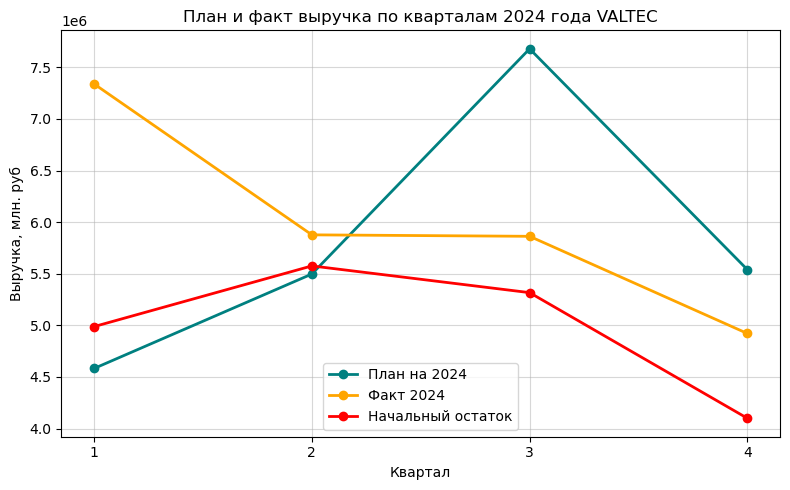

In [699]:
# Строим график по кварталам валтек (выручка??) и планы 2024
plt.figure(figsize=(8, 5))
plt.plot(quarter_sum_metalpl_2024_common.index, quarter_sum_metalpl_2024_common.values, marker='o', color='teal', linewidth=2, label='План на 2024')

# Добавляем данные за 2024
plt.plot(quarterly_valtec_df_itog_2024['Квартал'], quarterly_valtec_df_itog_2024['Выручка'], marker='o', color='orange', linewidth=2, label='Факт 2024')
plt.plot(quarterly_valtec_df_itog_2024['Квартал'], quarterly_valtec_df_itog_2024['Начальный_остаток'], marker='o', color='red', linewidth=2, label='Начальный остаток')

'''# Подписи к точкам
for x, y in zip(quarter_sum_metalpl_2024_common.index, quarter_sum_metalpl_2024_common.values):
    plt.text(x, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=9)

for x, y in zip(quarterly_valtec_df_itog['Квартал'], quarterly_valtec_df_itog_2024['Выручка']):
    plt.text(x, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=9)
'''
# Настроим график
plt.title('План и факт выручка по кварталам 2024 года VALTEC')
plt.xlabel('Квартал')
plt.ylabel('Выручка, млн. руб')
#plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x*1e-6)}M' if x >= 1e6 else f'{x*1e-6:.1f}M'))
plt.grid(alpha=0.5)
plt.xticks([1, 2, 3, 4])  # Убедимся, что только кварталы 1, 2, 3, 4 будут отображаться
plt.tight_layout()
plt.legend()
plt.show()

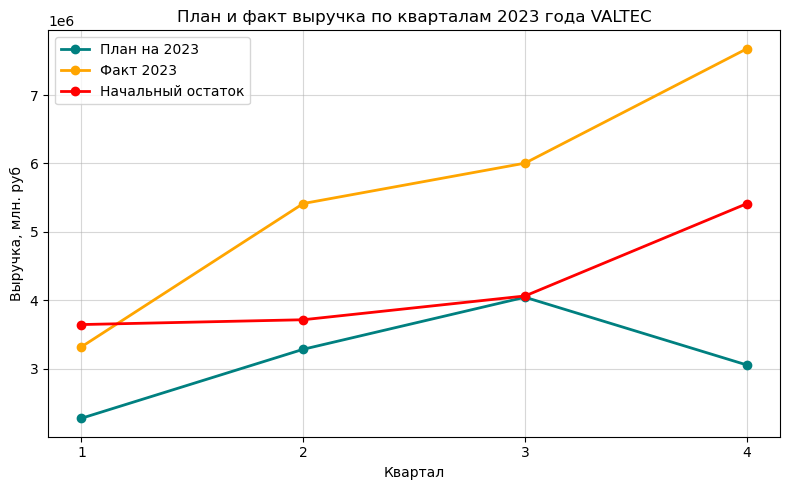

In [700]:
# Строим график по кварталам валтек (выручка??) и планы 2024
plt.figure(figsize=(8, 5))
plt.plot(quarter_sum_metalpl_2023_common.index, quarter_sum_metalpl_2023_common.values, marker='o', color='teal', linewidth=2, label='План на 2023')

# Добавляем данные за 2024
plt.plot(quarterly_valtec_df_itog_2023['Квартал'], quarterly_valtec_df_itog_2023['Выручка'], marker='o', color='orange', linewidth=2, label='Факт 2023')
plt.plot(quarterly_valtec_df_itog_2023['Квартал'], quarterly_valtec_df_itog_2023['Начальный_остаток'], marker='o', color='red', linewidth=2, label='Начальный остаток')

# Настроим график
plt.title('План и факт выручка по кварталам 2023 года VALTEC')
plt.xlabel('Квартал')
plt.ylabel('Выручка, млн. руб')
#plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x*1e-6)}M' if x >= 1e6 else f'{x*1e-6:.1f}M'))
plt.grid(alpha=0.5)
plt.xticks([1, 2, 3, 4])  # Убедимся, что только кварталы 1, 2, 3, 4 будут отображаться
plt.tight_layout()
plt.legend()
plt.show()

### А совпадает ли расход или выручка в valtec_df_common с фактом по 2023 году в metalpl_2024_common???

# Добавить файл с КОЛИЧЕСТВОМ по расходу и остаткам

### Как раз в metalpl_2024_common есть кол_во_факт_21, кол_во_факт_22, кол_во_план_23, кол_во_факт_23
Я могу сравнить сопоставляется ли это все кол_во со значениями расхода в количестве (из ведомости по движению)

In [377]:
# датасет по движение по количеству
df_amount = pd.read_excel('df_final полный движение с категориями.xlsx')

In [382]:
df_amount.columns = ['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток_шт', 'Приход_шт',
       'Расход_шт', 'Конечный_остаток_шт', 'Категория', 'Год']

In [612]:
valtec_df_common

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,Год,ABC_категория,ABC_2024,XYZ_2024,XYZ_all,Артикул
0,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2021-08-01,0.00,1743.33,784.50,871.66,833.09,1,2021,B,C,X,X,VTr.198.C.0410
1,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2022-08-01,47.29,896.67,674.25,269.71,746.25,1,2022,B,C,X,X,VTr.198.C.0410
2,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2023-08-01,534.02,485.83,631.33,388.52,724.52,1,2023,B,C,X,X,VTr.198.C.0410
3,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2024-08-01,1155.00,525.00,1575.00,105.00,1840.05,1,2024,B,C,X,X,VTr.198.C.0410
4,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2021-04-01,0.00,0.00,0.00,0.00,0.00,1,2021,B,C,X,X,VTr.198.C.0410
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50689,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2021-01-01,0.00,0.00,0.00,0.00,0.00,2,2021,C,B,Z,Z,VT.141.0.04
50690,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2022-01-01,0.00,0.00,0.00,0.00,0.00,2,2022,C,B,Z,Z,VT.141.0.04
50691,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2023-01-01,0.00,0.00,0.00,0.00,0.00,2,2023,C,B,Z,Z,VT.141.0.04
50692,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2024-01-01,0.00,0.00,0.00,0.00,0.00,2,2024,C,B,Z,Z,VT.141.0.04


In [613]:
valtec_df_common = valtec_df_common.merge(
    df_amount[['Код', 'Дата', 'Начальный_остаток_шт', 'Расход_шт', 'Приход_шт']], 
    on=['Код', 'Дата'], 
    how='left' 
)

In [614]:
valtec_df_common['Код'].nunique()

790

In [466]:
valtec_df_common_2023 = valtec_df_common[valtec_df_common['Год'] == 2023]
# Группируем по артикулу и считаем сумму расхода
valtec_df_common_2023_amount = valtec_df_common_2023.groupby(['Артикул'])[['Начальный_остаток_шт', 'Расход_шт', 'Приход_шт', 'Выручка']].sum().reset_index()

In [506]:
metalpl_2024_common

,Номенклатура,Код_пост,Артикул,Цена_24,кол_во_факт_21,кол_во_факт_22,кол_во_план_23,кол_во_факт_23,проект_24_шт_без_округл,проект_24_шт_итого_с_округл,сумма_проект_2024_руб,план_шт_1_кв,план_шт_2_кв,план_шт_3_кв,план_шт_4_кв,2024_прект_шт,сумма_1_кв,сумма_2_кв,сумма_3_кв,сумма_4_кв
0,"Соединитель пресс с накидной гайкой 20х1/2""",IV2222004,VTm.222.N.002004,177.1,30,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
1,"Соединитель пресс с накидной гайкой 20х3/4""",IV2222005,VTm.222.N.002005,261.5,NaN,10,NaN,25,23.25,23,6014.5,5,6,8,4,23,1307.5,1569,2092,1046
2,"Соединитель пресс с накидной гайкой 32х1 1/4""",IV2223207,VTm.222.N.003207,385.8,5,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
3,"Монтажная планка с водорозетками пресс 16х1/2""",IV2241604,VTm.224.N.001604,770.5,44,30,40,65,60.45,60,46230,12,14,20,14,60,9246,10787,15410,10787
4,Крестовина пресс 20х16х20х16,IV2412016,VTm.241.N.201620,475.7,5,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,Уплотнительное кольцо 22 FPM (Viton),TV9902200,VTi.990.I.000022,13.8,150,40,60,130,120.9,121,1669.8,24,29,40,28,121,331.2,400.2,552,386.4
786,Уплотнительное кольцо 28 FPM (Viton),TV9902800,VTi.990.I.000028,17.6,90,50,75,15,13.95,14,246.4,3,3,5,3,14,52.8,52.8,88,52.8
787,Уплотнительное кольцо 35 FPM (Viton),TV9903500,VTi.990.I.000035,22.7,10,NaN,6,NaN,0,0,0,0,0,0,0,0,0,0,0,0
788,Уплотнительное кольцо 42 FPM (Viton),TV9904200,VTi.990.I.000042,27.3,NaN,40,NaN,223,207.39,207,5651.1,41,50,68,48,207,1119.3,1365,1856.4,1310.4


In [507]:
mt2024 = metalpl_2024_common.iloc[:, [0, 1, 2, 4, 5, 6, 7, 8, 9]]

In [508]:
valtec_df_common_2023_amount.columns = ['Артикул', 'Начальный_остаток_шт_23', 'Расход_шт_23', 'Приход_шт_23', 'Выручка_23']

In [509]:
mt2024 = mt2024.merge(
    valtec_df_common_2023_amount[['Артикул','Начальный_остаток_шт_23', 'Расход_шт_23', 'Приход_шт_23', 'Выручка_23']], 
    on='Артикул', 
    how='left' 
)

In [510]:
cols_to_convert = [
    'кол_во_факт_21',
    'кол_во_факт_22',
    'кол_во_план_23',
    'кол_во_факт_23',
    'проект_24_шт_без_округл'
]

for col in cols_to_convert:
    mt2024[col] = pd.to_numeric(mt2024[col], errors='coerce')

In [511]:
mt2024 = mt2024.fillna(0)

C:\Users\Liza\AppData\Local\Temp\ipykernel_10316\3765470589.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  mt2024 = mt2024.fillna(0)


In [512]:
mt2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 790 entries, 0 to 789
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Номенклатура                 790 non-null    object 
 1   Код_пост                     790 non-null    object 
 2   Артикул                      790 non-null    object 
 3   кол_во_факт_21               790 non-null    float64
 4   кол_во_факт_22               790 non-null    float64
 5   кол_во_план_23               790 non-null    float64
 6   кол_во_факт_23               790 non-null    float64
 7   проект_24_шт_без_округл      790 non-null    float64
 8   проект_24_шт_итого_с_округл  790 non-null    int64  
 9   Начальный_остаток_шт_23      790 non-null    float64
 10  Расход_шт_23                 790 non-null    float64
 11  Приход_шт_23                 790 non-null    float64
 12  Выручка_23                   790 non-null    float64
dtypes: float64(9), int64

In [513]:
valtec_df_common_2021 = valtec_df_common[valtec_df_common['Год'] == 2021]
# Группируем по артикулу и считаем сумму расхода
valtec_df_common_2021_amount = valtec_df_common_2021.groupby(['Артикул'])[['Начальный_остаток_шт', 'Расход_шт', 'Приход_шт', 'Выручка']].sum().reset_index()

valtec_df_common_2021_amount.columns = ['Артикул', 'Начальный_остаток_шт_2021', 'Расход_шт_2021', 'Приход_шт_2021', 'Выручка_2021']

mt2024 = mt2024.merge(
    valtec_df_common_2021_amount[['Артикул','Начальный_остаток_шт_2021', 'Расход_шт_2021', 'Приход_шт_2021']], 
    on='Артикул', 
    how='left' 
)

In [515]:
valtec_df_common_2024 = valtec_df_common[valtec_df_common['Год'] == 2024]
# Группируем по артикулу и считаем сумму расхода
valtec_df_common_2024_amount = valtec_df_common_2024.groupby(['Артикул'])[['Начальный_остаток_шт', 'Расход_шт', 'Приход_шт', 'Выручка']].sum().reset_index()

valtec_df_common_2024_amount.columns = ['Артикул', 'Начальный_остаток_шт_2024', 'Расход_шт_2024', 'Приход_шт_2024', 'Выручка_2024']

mt2024 = mt2024.merge(
    valtec_df_common_2024_amount[['Артикул','Начальный_остаток_шт_2024', 'Расход_шт_2024', 'Приход_шт_2024']], 
    on='Артикул', 
    how='left' 
)

In [517]:
mt2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 790 entries, 0 to 789
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Номенклатура                 790 non-null    object 
 1   Код_пост                     790 non-null    object 
 2   Артикул                      790 non-null    object 
 3   кол_во_факт_21               790 non-null    float64
 4   кол_во_факт_22               790 non-null    float64
 5   кол_во_план_23               790 non-null    float64
 6   кол_во_факт_23               790 non-null    float64
 7   проект_24_шт_без_округл      790 non-null    float64
 8   проект_24_шт_итого_с_округл  790 non-null    int64  
 9   Начальный_остаток_шт_23      790 non-null    float64
 10  Расход_шт_23                 790 non-null    float64
 11  Приход_шт_23                 790 non-null    float64
 12  Выручка_23                   790 non-null    float64
 13  Начальный_остаток_шт

In [522]:
mae_plan_fact_2023_1 = (mt2024['кол_во_план_23'] - mt2024['кол_во_факт_23']).abs().mean()
print(mae_plan_fact_2023_1)

mae_plan_fact_2023 = (mt2024['кол_во_план_23'] - mt2024['Расход_шт_23']).abs().mean()
print(mae_plan_fact_2023)

mae_plan_fact_2024 = (mt2024['проект_24_шт_итого_с_округл'] - mt2024['Расход_шт_2024']).abs().mean()
print(mae_plan_fact_2024)

mae_plan_fact_2024_1 = (mt2024['проект_24_шт_без_округл'] - mt2024['Расход_шт_2024']).abs().mean()
print(mae_plan_fact_2024_1)

137.1759493670886
136.57341772151898
244.41772151898735
244.56522784810122


In [557]:
#Среднеквадратичная ошибка (RMSE):
rmse_23 = np.sqrt(((mt2024['кол_во_план_23'] - mt2024['Расход_шт_23'])**2).mean())
print(rmse_23)

rmse_24 = np.sqrt(((mt2024['проект_24_шт_итого_с_округл'] - mt2024['Расход_шт_2024'])**2).mean())
print(rmse_24)

1329.4518490668784
4673.232269864325


# Средняя абсолютная процентная ошибка (MAPE):

In [583]:
mt2024_err2023_less_200 = mt2024_sorted[mt2024_sorted['abs_error_2023'] < 200]

In [584]:
df_nonzero_23 = mt2024_err2023_less_200[mt2024_err2023_less_200['Расход_шт_23'] != 0]
mape_23 = (abs(df_nonzero_23['кол_во_план_23'] - df_nonzero_23['Расход_шт_23']) / df_nonzero_23['Расход_шт_23']).mean() * 100
mape_23

95.57037124916626

In [561]:
df_nonzero_24 = mt2024[mt2024['Расход_шт_2024'] != 0]
mape_24 = (abs(df_nonzero_24['проект_24_шт_итого_с_округл'] - df_nonzero_24['Расход_шт_2024']) / df_nonzero_24['Расход_шт_2024']).mean() * 100
mape_24

159.34403312737578

In [590]:
df_nonzero_23 = mt2024[mt2024['Расход_шт_23'] != 0]
# Рассчитаем процентную ошибку
df_nonzero_23['PE23'] = (df_nonzero_23['Расход_шт_23'] - df_nonzero_23['кол_во_план_23']) / df_nonzero_23['Расход_шт_23'] * 100
# Рассчитаем среднюю процентную ошибку
mean_pe_23 = df_nonzero_23['PE23'].mean()
print(f'Средняя процентная ошибка: {mean_pe_23:.2f}%')


Средняя процентная ошибка: 30.74%


C:\Users\Liza\AppData\Local\Temp\ipykernel_10316\2565347372.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nonzero_23['PE23'] = (df_nonzero_23['Расход_шт_23'] - df_nonzero_23['кол_во_план_23']) / df_nonzero_23['Расход_шт_23'] * 100


In [591]:
df_nonzero_24 = mt2024[mt2024['Расход_шт_2024'] != 0]
# Рассчитаем процентную ошибку
df_nonzero_24['PE24'] = (df_nonzero_24['Расход_шт_2024'] - df_nonzero_24['проект_24_шт_итого_с_округл']) / df_nonzero_24['Расход_шт_2024'] * 100
# Рассчитаем среднюю процентную ошибку
mean_pe_24 = df_nonzero_24['PE24'].mean()
print(f'Средняя процентная ошибка: {mean_pe_24:.2f}%')


Средняя процентная ошибка: -79.29%


C:\Users\Liza\AppData\Local\Temp\ipykernel_10316\913151820.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nonzero_24['PE24'] = (df_nonzero_24['Расход_шт_2024'] - df_nonzero_24['проект_24_шт_итого_с_округл']) / df_nonzero_24['Расход_шт_2024'] * 100


In [589]:
df_nonzero_23

,Номенклатура,Код_пост,Артикул,кол_во_факт_21,кол_во_факт_22,кол_во_план_23,кол_во_факт_23,проект_24_шт_без_округл,проект_24_шт_итого_с_округл,Начальный_остаток_шт_23,...,Выручка_23,Начальный_остаток_шт_2021,Расход_шт_2021,Приход_шт_2021,Начальный_остаток_шт_2024,Расход_шт_2024,Приход_шт_2024,abs_error_2023,abs_error_2024,PE23
0,"Соединитель пресс с накидной гайкой 20х1/2""",IV2222004,VTm.222.N.002004,30.0,0.0,0.0,0.0,0.00,0,0.0,...,0.00,0.0,30.0,30.0,45.0,10.0,10.0,0.0,10.0,NaN
1,"Соединитель пресс с накидной гайкой 20х3/4""",IV2222005,VTm.222.N.002005,0.0,10.0,0.0,25.0,23.25,23,14.0,...,6211.84,80.0,40.0,0.0,0.0,20.0,20.0,25.0,3.0,100.000000
3,"Монтажная планка с водорозетками пресс 16х1/2""",IV2241604,VTm.224.N.001604,44.0,30.0,40.0,65.0,60.45,60,41.0,...,60646.44,26.0,41.0,44.0,150.0,118.0,119.0,41.0,58.0,50.617284
5,"Водорозетка пресс 16х1/2"" (удлиненная)",IV2541604H,VTm.254H.N.001604,0.0,30.0,0.0,16.0,14.88,15,74.0,...,6670.73,0.0,0.0,0.0,65.0,45.0,55.0,27.0,30.0,100.000000
7,Угольник радиаторный пресс с латунной хром. тр...,IV2811615L,VTm.281.LN.001615,0.0,0.0,0.0,0.0,0.00,0,0.0,...,0.00,40.0,10.0,10.0,0.0,81.0,81.0,0.0,81.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
781,Обвод вн.-вн. нерж. сталь 22х22,TV9712200,VTi.971.I.002222,30.0,0.0,12.0,5.0,4.65,5,91.0,...,1852.87,70.0,22.0,39.0,68.0,9.0,6.0,7.0,4.0,-140.000000
782,"Обвод, вн.-вн. нерж. сталь 28х28",TV9712800,VTi.971.I.002828,15.0,15.0,0.0,5.0,4.65,5,32.0,...,2760.00,3.0,10.0,10.0,15.0,3.0,2.0,5.0,2.0,100.000000
785,Уплотнительное кольцо 22 FPM (Viton),TV9902200,VTi.990.I.000022,150.0,40.0,60.0,130.0,120.90,121,198.0,...,2035.50,299.0,120.0,150.0,147.0,68.0,65.0,78.0,53.0,56.521739
787,Уплотнительное кольцо 35 FPM (Viton),TV9903500,VTi.990.I.000035,10.0,0.0,6.0,0.0,0.00,0,36.0,...,0.00,38.0,17.0,10.0,90.0,3.0,10.0,6.0,3.0,-inf


# Абсолютная ошибка 2023 и 2024

In [523]:
#Абсоютная ошибка
mt2024['abs_error_2023'] = abs(mt2024['кол_во_план_23'] - mt2024['Расход_шт_23'])
mt2024['abs_error_2024'] = abs(mt2024['проект_24_шт_итого_с_округл'] - mt2024['Расход_шт_2024'])

In [ ]:
#sample_df = sample_df.sort_values('Артикул')

plt.figure(figsize=(10, 6))
plt.plot(df['Артикул'], df['abs_error'], marker='o', color='green', linestyle='-', markersize=5)
plt.title('Абсолютная ошибка по артикулам')
plt.xlabel('Артикул')
plt.ylabel('Абсолютная ошибка')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()


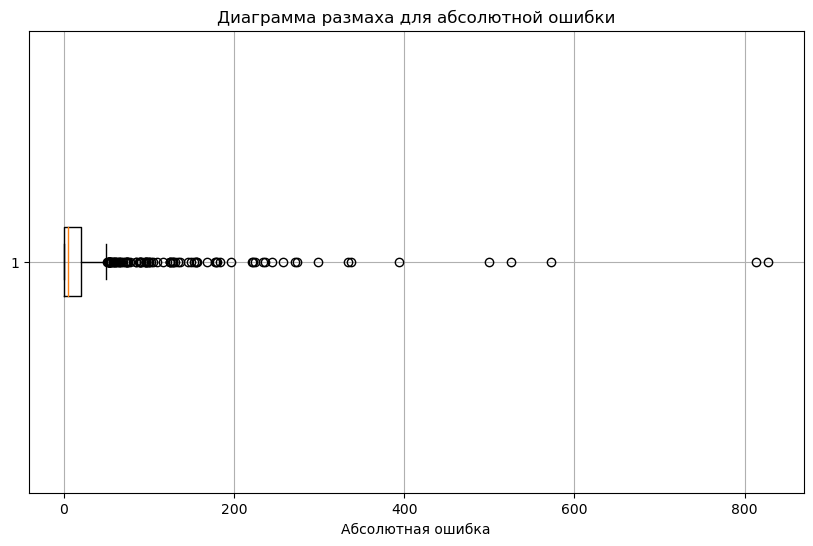

In [566]:
plt.figure(figsize=(10, 6))
plt.boxplot(mt2024_sorted[mt2024_sorted['abs_error_2023'] < 1000]['abs_error_2023'], vert=False)
plt.title('Диаграмма размаха для абсолютной ошибки')
plt.xlabel('Абсолютная ошибка')
plt.grid(True)
plt.show()


In [555]:
mt2024_sorted[mt2024_sorted['abs_error_2024'] < 500]['abs_error_2024'].mean()

27.377260981912144

In [528]:
mt2024_sorted = mt2024.sort_values('abs_error_2023')

In [537]:
mt2024_sorted[mt2024_sorted['abs_error_2023'] < 100].describe()

,кол_во_факт_21,кол_во_факт_22,кол_во_план_23,кол_во_факт_23,проект_24_шт_без_округл,проект_24_шт_итого_с_округл,Начальный_остаток_шт_23,Расход_шт_23,Приход_шт_23,Выручка_23,Начальный_остаток_шт_2021,Расход_шт_2021,Приход_шт_2021,Начальный_остаток_шт_2024,Расход_шт_2024,Приход_шт_2024,abs_error_2023,abs_error_2024
count,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000
mean,45.339237,25.009537,23.787466,29.174387,27.132180,27.170300,47.252044,28.877384,29.809264,18091.338828,69.540872,44.380381,46.408719,51.262943,35.652589,34.245232,12.514986,23.525886
std,173.397125,107.028977,99.966917,101.913157,94.779236,94.755604,91.827128,98.861037,103.868616,56977.572520,168.043384,172.893703,174.963155,133.304728,116.419705,112.475105,19.040251,76.471423
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,5.000000,1.000000,0.000000,5.000000,4.650000,5.000000,9.000000,5.000000,5.000000,2209.605000,11.000000,5.000000,5.000000,8.000000,4.000000,3.000000,5.000000,5.000000
75%,30.000000,13.000000,12.000000,24.750000,23.017500,22.750000,68.000000,23.000000,25.000000,11593.950000,79.000000,27.750000,30.000000,63.000000,20.750000,20.000000,15.750000,18.000000
max,2800.000000,1640.000000,1900.000000,2080.000000,1934.400000,1934.000000,965.000000,1985.000000,2135.000000,819065.760000,2534.000000,2818.200000,2783.000000,2449.000000,1756.000000,1714.000000,99.000000,1186.000000


In [544]:
mt2024_sorted[mt2024_sorted['abs_error_2023'] < 350]['abs_error_2023'].mean()

20.8745148771022

### Ошибка между файлами незначительная: мой файл по количеству и Елены Сергеевны факты в планах по валтеку по 2021 году

In [494]:
#Абсоютная ошибка
#df['abs_error'] = abs(df['кол_во_факт_21'] - df['Расход_шт_2021'])

mae_fact_2021 = (mt2024_1['кол_во_факт_21'] - mt2024_1['Расход_шт_2021']).abs().mean()
print(mae_fact_2021)

17.712911392405065


In [496]:
mae_fact_2021 = (mt2024_1['кол_во_факт_23'] - mt2024_1['Расход_шт']).abs().mean()
print(mae_fact_2021)

10.562025316455696


# Создание план-факт дф по кварталам 2023 и 2024
### - Расчет ошибок по кварталам
### - Переделать только для valtec_df_common ABC-XYZ-анализ

In [ ]:
valtec_df_common
metalpl_2024_common
metalpl_2023_common


In [629]:
valtec_df_common['Квартал'] = valtec_df_common['Дата'].dt.quarter

In [ ]:
valtec_df_common #40290 

In [626]:
plan_q_metalpl_2023_common = metalpl_2023_common[[
       'Артикул', 'проект_2023',
       'план_кол_во_1_кв', 'план_кол_во_2_кв',
       'план_кол_во_3_кв', 'план_кол_во_4_кв']]

plan_q_metalpl_2024_common = metalpl_2024_common[[
       'Артикул', 'проект_24_шт_итого_с_округл',
       'план_шт_1_кв', 'план_шт_2_кв', 'план_шт_3_кв', 'план_шт_4_кв']]

In [632]:
valtec_df_common_2023 = valtec_df_common[valtec_df_common['Год'] == 2023]
valtec_df_common_2024 = valtec_df_common[valtec_df_common['Год'] == 2024]

In [666]:
r_2023_amount = valtec_df_common_2023.groupby(['Артикул'])[['Расход_шт']].sum().reset_index()
r_2024_amount = valtec_df_common_2024.groupby(['Артикул'])[['Расход_шт']].sum().reset_index()

r_2023_amount[r_2023_amount['Расход_шт'] > 0] # 574
r_2024_amount[r_2024_amount['Расход_шт'] > 0] # 513

nn23 = set(r_2023_amount[r_2023_amount['Расход_шт'] > 0]['Артикул'].unique())
nn24 = set(r_2024_amount[r_2024_amount['Расход_шт'] > 0]['Артикул'].unique())
nn_com = nn23 & nn24
print('nn23:', len(nn23))
print('nn24:', len(nn24))
print('nn_com:', len(nn_com))

nn23: 574
nn24: 513
nn_com: 424


### 2023 год кварталы и ошибки

In [635]:
# 1 кв
q_1_2023 = valtec_df_common_2023[valtec_df_common_2023['Квартал'] == 1].groupby('Артикул')['Расход_шт'].sum().reset_index()
q_1_2023 = q_1_2023.rename(columns={'Расход_шт': 'Факт_1_кв'})
# 2
q_2_2023 = valtec_df_common_2023[valtec_df_common_2023['Квартал'] == 2].groupby('Артикул')['Расход_шт'].sum().reset_index()
q_2_2023 = q_2_2023.rename(columns={'Расход_шт': 'Факт_2_кв'})
# 3
q_3_2023 = valtec_df_common_2023[valtec_df_common_2023['Квартал'] == 3].groupby('Артикул')['Расход_шт'].sum().reset_index()
q_3_2023 = q_3_2023.rename(columns={'Расход_шт': 'Факт_3_кв'})
# 4
q_4_2023 = valtec_df_common_2023[valtec_df_common_2023['Квартал'] == 4].groupby('Артикул')['Расход_шт'].sum().reset_index()
q_4_2023 = q_4_2023.rename(columns={'Расход_шт': 'Факт_4_кв'})

In [650]:
quarter_valtec_2023 = q_1_2023.merge(q_2_2023, on='Артикул', how='outer')\
                   .merge(q_3_2023, on='Артикул', how='outer')\
                   .merge(q_4_2023, on='Артикул', how='outer')

In [653]:
plan_q_metalpl_2023_common.columns

Index(['Артикул', 'проект_2023', 'план_кол_во_1_кв', 'план_кол_во_2_кв',
       'план_кол_во_3_кв', 'план_кол_во_4_кв'],
      dtype='object')

In [654]:
plan_fact_2023 = quarter_valtec_2023.merge(
    plan_q_metalpl_2023_common[['Артикул', 'проект_2023', 'план_кол_во_1_кв', 'план_кол_во_2_кв', 'план_кол_во_3_кв', 'план_кол_во_4_кв']], 
    on='Артикул', 
    how='outer' 
)

In [657]:
plan_fact_2023.columns

Index(['Артикул', 'Факт_1_кв', 'Факт_2_кв', 'Факт_3_кв', 'Факт_4_кв',
       'проект_2023', 'план_кол_во_1_кв', 'план_кол_во_2_кв',
       'план_кол_во_3_кв', 'план_кол_во_4_кв'],
      dtype='object')

In [665]:
print('2023 год:')
for q in ['1_кв', '2_кв', '3_кв', '4_кв']:
    y_true = plan_fact_2023[f'Факт_{q}']      # фактические значения
    y_pred = plan_fact_2023[f'план_кол_во_{q}']      # плановые значения
    
    # MAE и RMSE — считаем по всем
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred) #Root Mean Squared Error (корень!!) squared=False

    # MAPE и PE — исключаем нули в факте
    mask = y_true != 0
    mape = (np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])).mean() * 100
    pe = ((y_true[mask] - y_pred[mask]) / y_true[mask] * 100).mean()

    print(f'Квартал {q}:')
    print(f'  MAE:  {mae:.2f}')
    print(f'  RMSE: {rmse:.2f}')
    print(f'  MAPE: {mape:.2f}%')
    print(f'  PE:   {pe:.2f}%')


2023 год:
Квартал 1_кв:
  MAE:  31.90
  RMSE: 439.10
  MAPE: 111.13%
  PE:   -10.66%
Квартал 2_кв:
  MAE:  50.58
  RMSE: 838.98
  MAPE: 95.71%
  PE:   6.73%
Квартал 3_кв:
  MAE:  29.21
  RMSE: 311.21
  MAPE: 125.34%
  PE:   -18.90%
Квартал 4_кв:
  MAE:  35.80
  RMSE: 324.01
  MAPE: 98.95%
  PE:   3.96%


In [705]:
# Используем данные по всем кварталам за 2024 год
y_true = plan_fact_2023[['Факт_1_кв', 'Факт_2_кв', 'Факт_3_кв', 'Факт_4_кв']].values.flatten()  # фактические значения
y_pred = plan_fact_2023[['план_кол_во_1_кв', 'план_кол_во_2_кв', 'план_кол_во_3_кв', 'план_кол_во_4_кв']].values.flatten()  # плановые значения

# MAE и RMSE — считаем по всем данным
mae = mean_absolute_error(y_true, y_pred)
rmse = root_mean_squared_error(y_true, y_pred)  # Корень из MSE

# MAPE и PE — исключаем нули в факте
mask = y_true != 0
mape = (np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])).mean() * 100
pe = ((y_true[mask] - y_pred[mask]) / y_true[mask] * 100).mean()

print('2023 год (по всему году):')
print(f'  MAE:  {mae:.2f}')
print(f'  RMSE: {rmse:.2f}')
print(f'  MAPE: {mape:.2f}%')
print(f'  PE:   {pe:.2f}%')

2023 год (по всему году):
  MAE:  36.88
  RMSE: 524.05
  MAPE: 108.14%
  PE:   -4.90%


### 2024 год кварталы и ошибки

In [ ]:
valtec_df_common_2024
plan_q_metalpl_2024_common

In [668]:
# 1 квартал
q_1_2024 = valtec_df_common_2024[valtec_df_common_2024['Квартал'] == 1].groupby('Артикул')['Расход_шт'].sum().reset_index()
q_1_2024 = q_1_2024.rename(columns={'Расход_шт': 'Факт_1_кв'})

# 2 квартал
q_2_2024 = valtec_df_common_2024[valtec_df_common_2024['Квартал'] == 2].groupby('Артикул')['Расход_шт'].sum().reset_index()
q_2_2024 = q_2_2024.rename(columns={'Расход_шт': 'Факт_2_кв'})

# 3 квартал
q_3_2024 = valtec_df_common_2024[valtec_df_common_2024['Квартал'] == 3].groupby('Артикул')['Расход_шт'].sum().reset_index()
q_3_2024 = q_3_2024.rename(columns={'Расход_шт': 'Факт_3_кв'})

# 4 квартал
q_4_2024 = valtec_df_common_2024[valtec_df_common_2024['Квартал'] == 4].groupby('Артикул')['Расход_шт'].sum().reset_index()
q_4_2024 = q_4_2024.rename(columns={'Расход_шт': 'Факт_4_кв'})

# Объединяем все кварталы
quarter_valtec_2024 = q_1_2024.merge(q_2_2024, on='Артикул', how='outer')\
                              .merge(q_3_2024, on='Артикул', how='outer')\
                              .merge(q_4_2024, on='Артикул', how='outer')


In [670]:
plan_q_metalpl_2024_common.columns

Index(['Артикул', 'проект_24_шт_итого_с_округл', 'план_шт_1_кв',
       'план_шт_2_кв', 'план_шт_3_кв', 'план_шт_4_кв'],
      dtype='object')

In [671]:
plan_fact_2024 = quarter_valtec_2024.merge(
    plan_q_metalpl_2024_common[[
    'Артикул', 'проект_24_шт_итого_с_округл', 'план_шт_1_кв',
    'план_шт_2_кв', 'план_шт_3_кв', 'план_шт_4_кв']], 
    on='Артикул', 
    how='outer' 
)

In [672]:
plan_fact_2024.columns

Index(['Артикул', 'Факт_1_кв', 'Факт_2_кв', 'Факт_3_кв', 'Факт_4_кв',
       'проект_24_шт_итого_с_округл', 'план_шт_1_кв', 'план_шт_2_кв',
       'план_шт_3_кв', 'план_шт_4_кв'],
      dtype='object')

In [673]:
print('2024 год:')
for q in ['1_кв', '2_кв', '3_кв', '4_кв']:
    y_true = plan_fact_2024[f'Факт_{q}']      # фактические значения
    y_pred = plan_fact_2024[f'план_шт_{q}']      # плановые значения
    
    # MAE и RMSE — считаем по всем
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred) #Root Mean Squared Error (корень!!) squared=False

    # MAPE и PE — исключаем нули в факте
    mask = y_true != 0
    mape = (np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])).mean() * 100
    pe = ((y_true[mask] - y_pred[mask]) / y_true[mask] * 100).mean()

    print(f'Квартал {q}:')
    print(f'  MAE:  {mae:.2f}')
    print(f'  RMSE: {rmse:.2f}')
    print(f'  MAPE: {mape:.2f}%')
    print(f'  PE:   {pe:.2f}%')


2024 год:
Квартал 1_кв:
  MAE:  56.05
  RMSE: 870.69
  MAPE: 123.60%
  PE:   -41.48%
Квартал 2_кв:
  MAE:  57.24
  RMSE: 1025.35
  MAPE: 152.74%
  PE:   -82.15%
Квартал 3_кв:
  MAE:  65.33
  RMSE: 1018.36
  MAPE: 162.31%
  PE:   -91.90%
Квартал 4_кв:
  MAE:  84.11
  RMSE: 1780.34
  MAPE: 155.98%
  PE:   -74.89%


In [701]:
# Используем данные по всем кварталам за 2024 год
y_true = plan_fact_2024[['Факт_1_кв', 'Факт_2_кв', 'Факт_3_кв', 'Факт_4_кв']].values.flatten()  # фактические значения
y_pred = plan_fact_2024[['план_шт_1_кв', 'план_шт_2_кв', 'план_шт_3_кв', 'план_шт_4_кв']].values.flatten()  # плановые значения

# MAE и RMSE — считаем по всем данным
mae = mean_absolute_error(y_true, y_pred)
rmse = root_mean_squared_error(y_true, y_pred)  # Корень из MSE

# MAPE и PE — исключаем нули в факте
mask = y_true != 0
mape = (np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])).mean() * 100
pe = ((y_true[mask] - y_pred[mask]) / y_true[mask] * 100).mean()

print('2024 год (по всему году):')
print(f'  MAE:  {mae:.2f}')
print(f'  RMSE: {rmse:.2f}')
print(f'  MAPE: {mape:.2f}%')
print(f'  PE:   {pe:.2f}%')

2024 год (по всему году):
  MAE:  65.68
  RMSE: 1226.39
  MAPE: 148.93%
  PE:   -72.93%


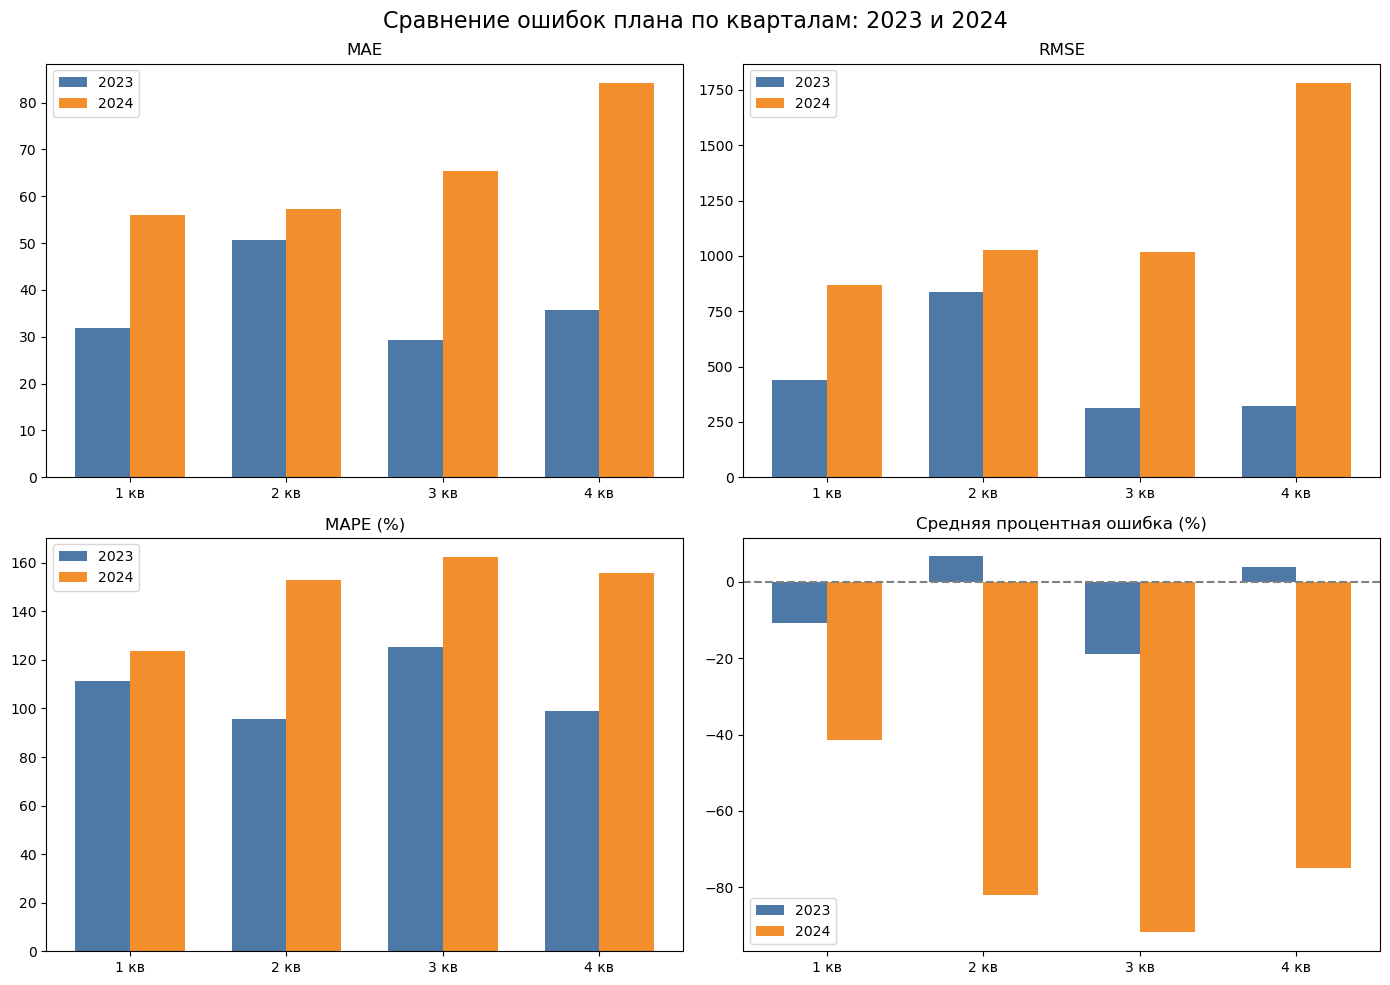

In [686]:
quarters = ['1 кв', '2 кв', '3 кв', '4 кв']
mae_2023 = [31.90, 50.58, 29.21, 35.80]
mae_2024 = [56.05, 57.24, 65.33, 84.11]

rmse_2023 = [439.10, 838.98, 311.21, 324.01]
rmse_2024 = [870.69, 1025.35, 1018.36, 1780.34]

mape_2023 = [111.13, 95.71, 125.34, 98.95]
mape_2024 = [123.60, 152.74, 162.31, 155.98]

pe_2023 = [-10.66, 6.73, -18.90, 3.96]
pe_2024 = [-41.48, -82.15, -91.90, -74.89]

x = np.arange(len(quarters))
width = 0.35

# Цвета: мягкий синий и коралловый
color_2023 = '#4E79A7' #'teal' #'#4E79A7'  # синий
color_2024 = '#F28E2B'#'salmon' #'#F28E2B'  # оранжево-коралловый

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Сравнение ошибок плана по кварталам: 2023 и 2024', fontsize=16)

# MAE
axs[0, 0].bar(x - width/2, mae_2023, width, label='2023', color=color_2023)
axs[0, 0].bar(x + width/2, mae_2024, width, label='2024', color=color_2024)
axs[0, 0].set_title('MAE')
axs[0, 0].set_xticks(x)
axs[0, 0].set_xticklabels(quarters)
axs[0, 0].legend()

# RMSE
axs[0, 1].bar(x - width/2, rmse_2023, width, label='2023', color=color_2023)
axs[0, 1].bar(x + width/2, rmse_2024, width, label='2024', color=color_2024)
axs[0, 1].set_title('RMSE')
axs[0, 1].set_xticks(x)
axs[0, 1].set_xticklabels(quarters)
axs[0, 1].legend()

# MAPE
axs[1, 0].bar(x - width/2, mape_2023, width, label='2023', color=color_2023)
axs[1, 0].bar(x + width/2, mape_2024, width, label='2024', color=color_2024)
axs[1, 0].set_title('MAPE (%)')
axs[1, 0].set_xticks(x)
axs[1, 0].set_xticklabels(quarters)
axs[1, 0].legend()

# PE
axs[1, 1].bar(x - width/2, pe_2023, width, label='2023', color=color_2023)
axs[1, 1].bar(x + width/2, pe_2024, width, label='2024', color=color_2024)
axs[1, 1].set_title('Средняя процентная ошибка (%)')
axs[1, 1].set_xticks(x)
axs[1, 1].set_xticklabels(quarters)
axs[1, 1].axhline(0, color='gray', linestyle='--')
axs[1, 1].legend()

plt.tight_layout()
plt.show()


### Ошибки с трендами - наверное не нужно такое

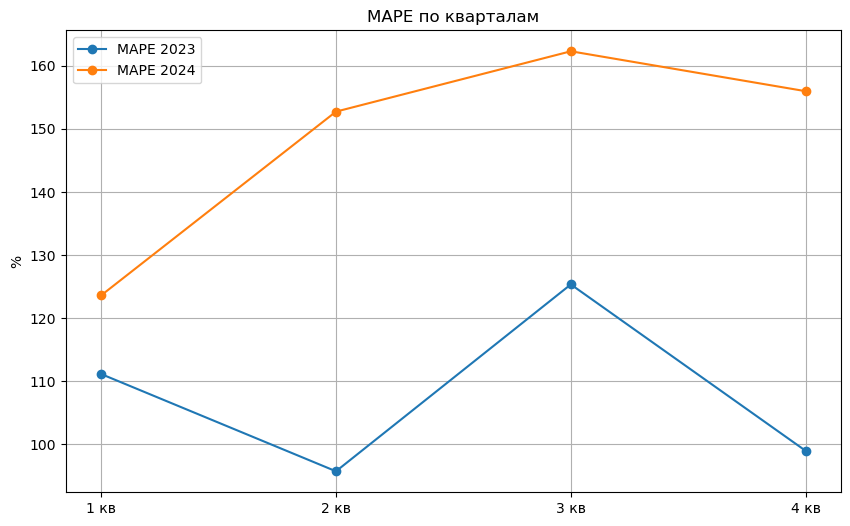

In [675]:
plt.figure(figsize=(10,6))
plt.plot(quarters, mape_2023, marker='o', label='MAPE 2023')
plt.plot(quarters, mape_2024, marker='o', label='MAPE 2024')
plt.title('MAPE по кварталам')
plt.ylabel('%')
plt.grid(True)
plt.legend()
plt.show()

In [706]:
plan_fact_2024.to_excel('valtec_plan_fact_2024.xlsx', index=False)
plan_fact_2023.to_excel('valtec_plan_fact_2023.xlsx', index=False)

C:\Users\Liza\AppData\Local\Temp\ipykernel_10316\4267689296.py:1: UserWarning: Pandas requires version '3.0.5' or newer of 'xlsxwriter' (version '3.0.3' currently installed).
  plan_fact_2024.to_excel('valtec_plan_fact_2024.xlsx', index=False)
C:\Users\Liza\AppData\Local\Temp\ipykernel_10316\4267689296.py:2: UserWarning: Pandas requires version '3.0.5' or newer of 'xlsxwriter' (version '3.0.3' currently installed).
  plan_fact_2023.to_excel('valtec_plan_fact_2023.xlsx', index=False)


In [735]:
valtec_df_common

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,Год,ABC_категория,ABC_2024,XYZ_2024,XYZ_all,Артикул,Начальный_остаток_шт,Расход_шт,Приход_шт,Квартал
0,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2021-08-01,0.00,1743.33,784.50,871.66,833.09,1,2021,B,C,X,X,VTr.198.C.0410,0.0,18.0,40.0,3
1,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2022-08-01,47.29,896.67,674.25,269.71,746.25,1,2022,B,C,X,X,VTr.198.C.0410,1.0,15.0,20.0,3
2,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2023-08-01,534.02,485.83,631.33,388.52,724.52,1,2023,B,C,X,X,VTr.198.C.0410,11.0,13.0,10.0,3
3,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2024-08-01,1155.00,525.00,1575.00,105.00,1840.05,1,2024,B,C,X,X,VTr.198.C.0410,22.0,30.0,10.0,3
4,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2021-04-01,0.00,0.00,0.00,0.00,0.00,1,2021,B,C,X,X,VTr.198.C.0410,0.0,0.0,0.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40285,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2021-01-01,0.00,0.00,0.00,0.00,0.00,2,2021,C,B,Z,Z,VT.141.0.04,0.0,0.0,0.0,1
40286,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2022-01-01,0.00,0.00,0.00,0.00,0.00,2,2022,C,B,Z,Z,VT.141.0.04,0.0,0.0,0.0,1
40287,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2023-01-01,0.00,0.00,0.00,0.00,0.00,2,2023,C,B,Z,Z,VT.141.0.04,0.0,0.0,0.0,1
40288,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2024-01-01,0.00,0.00,0.00,0.00,0.00,2,2024,C,B,Z,Z,VT.141.0.04,0.0,0.0,0.0,1


# ABC-XYZ-анализ VALTEC

In [736]:
# Шаг 1: Группировка по 'Код' или 'Номенклатура', расчет суммарной выручки для каждого элемента
df_sales = valtec_df_common.groupby(['Код'])['Выручка'].sum().reset_index()
# Шаг 2: Сортировка по выручке по убыванию
df_sales = df_sales.sort_values(by='Выручка', ascending=False)
# Шаг 3: Накопление суммы выручки и расчет кумулятивного процента
df_sales['Кумулятивная_сумма'] = df_sales['Выручка'].cumsum()
df_sales['Кумулятивный_процент'] = df_sales['Кумулятивная_сумма'] / df_sales['Выручка'].sum() * 100

In [740]:
df_sales_1 = df_sales.reset_index(drop=True)

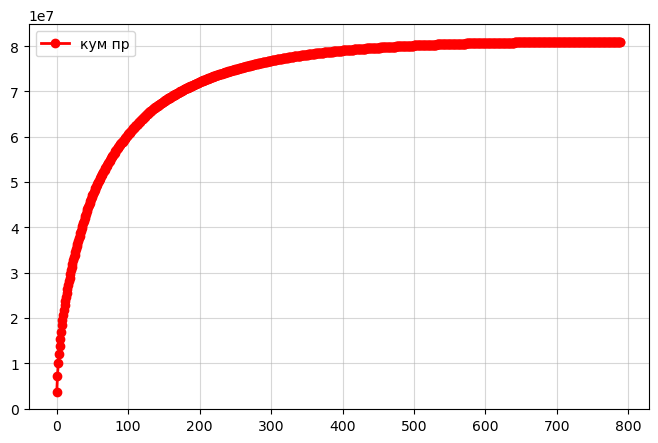

In [741]:
plt.figure(figsize=(8, 5))
plt.plot(df_sales_1['Кумулятивная_сумма'].index, df_sales_1['Кумулятивная_сумма'], marker='o', color='red', linewidth=2, label='кум пр')
# Настроим график
#plt.title('План и факт выручка по кварталам 2023 года VALTEC')
#plt.xlabel('Квартал')
#plt.ylabel('Выручка, млн. руб')
#plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x*1e-6)}M' if x >= 1e6 else f'{x*1e-6:.1f}M'))
plt.grid(alpha=0.5)
#plt.xticks([1, 2, 3, 4])  # Убедимся, что только кварталы 1, 2, 3, 4 будут отображаться
#plt.tight_layout()
plt.legend()
plt.show()

In [742]:
# Шаг 4: Классификация элементов на A, B, C
def abc_classification(row):
    if row['Кумулятивный_процент'] <= 80:
        return 'A'
    elif row['Кумулятивный_процент'] <= 95:
        return 'B'
    else:
        return 'C'

df_sales['ABC_valtec'] = df_sales.apply(abc_classification, axis=1)
# Объединяем результат ABC-анализа с df_final
valtec_df_common = valtec_df_common.merge(df_sales[['Код', 'ABC_valtec']], on=['Код'], how='left')

In [748]:
unique_codes_in_abc = df_sales.groupby('ABC_valtec')['Код'].nunique().reset_index()
unique_codes_in_abc.columns = ['ABC_valtec', 'Количество уникальных кодов']
unique_codes_in_abc

,ABC_valtec,Количество уникальных кодов
0,A,125
1,B,179
2,C,486


### XYZ

In [750]:
df_sko_valtec = valtec_df_common.groupby('Код')['Расход_шт'].agg(['std', 'mean']).reset_index()
df_sko_valtec['КВ_все'] = (df_sko_valtec['std'] / df_sko_valtec['mean']) * 100

In [755]:
df_sko_valtec_1 = df_sko_valtec.sort_values(by='КВ_все', ascending=True).reset_index(drop=True)

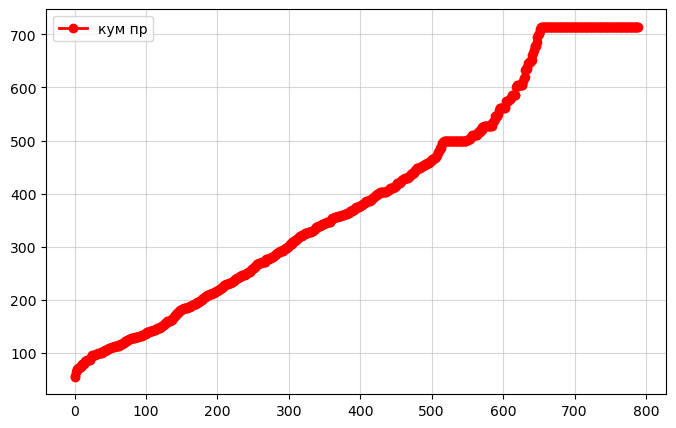

In [756]:
plt.figure(figsize=(8, 5))
plt.plot(df_sko_valtec_1['КВ_все'].index, df_sko_valtec_1['КВ_все'], marker='o', color='red', linewidth=2, label='кум пр')
# Настроим график
#plt.title('План и факт выручка по кварталам 2023 года VALTEC')
#plt.xlabel('Квартал')
#plt.ylabel('Выручка, млн. руб')
#plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x*1e-6)}M' if x >= 1e6 else f'{x*1e-6:.1f}M'))
plt.grid(alpha=0.5)
#plt.xticks([1, 2, 3, 4])  # Убедимся, что только кварталы 1, 2, 3, 4 будут отображаться
#plt.tight_layout()
plt.legend()
plt.show()

In [757]:
# Функция для классификации на основе квартилей (немного под вопросом, у гпт <= вместо <)
def xyz_classification_by_quantile(cv_value, q1, q2):
    if cv_value < q1:  # Группа X: меньше первого квартиля
        return 'X'
    elif cv_value < q2:  # Группа Y: между первым и вторым квартилем
        return 'Y'
    else:  # Группа Z: больше второго квартиля
        return 'Z'

# Для каждого датафрейма находим квартили для соответствующего столбца
q1_all, q2_all, q3_all = df_sko_valtec['КВ_все'].quantile([0.25, 0.5, 0.75])

# Применяем функцию классификации на основе квартилей
df_sko_valtec['XYZ_valtec'] = df_sko_valtec['КВ_все'].apply(xyz_classification_by_quantile, args=(q1_all, q2_all))

In [758]:
valtec_df_common = valtec_df_common.merge(df_sko_valtec[['Код', 'XYZ_valtec']], on='Код', how='left')

In [760]:
unique_codes_in_xyz = valtec_df_common.groupby('XYZ_valtec')['Код'].nunique().reset_index()
unique_codes_in_xyz.columns = ['XYZ_valtec', 'Количество уникальных кодов']
unique_codes_in_xyz

,XYZ_valtec,Количество уникальных кодов
0,X,198
1,Y,197
2,Z,395


In [761]:
# Оставим только нужные столбцы и удалим дубликаты по 'Код', 'ABC_2024', 'XYZ_2024'
unique_codes_v = valtec_df_common[['Код', 'ABC_valtec', 'XYZ_valtec']].drop_duplicates().reset_index(drop=True)

abc_xyz_matrix_v = unique_codes_v.pivot_table(index='ABC_valtec',
                                          columns='XYZ_valtec',
                                          values='Код',
                                          aggfunc='nunique',
                                          fill_value=0)
abc_xyz_matrix_v

XYZ_valtec,X,Y,Z
ABC_valtec,,,
A,91,20,14
B,67,62,50
C,40,115,331


In [763]:
valtec_df_common.columns

Index(['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток', 'Приход',
       'Расход', 'Конечный_остаток', 'Выручка', 'Категория', 'Год',
       'ABC_категория', 'ABC_2024', 'XYZ_2024', 'XYZ_all', 'Артикул',
       'Начальный_остаток_шт', 'Расход_шт', 'Приход_шт', 'Квартал',
       'ABC_valtec', 'XYZ_valtec'],
      dtype='object')

In [767]:
valtec_df_common_new = valtec_df_common.copy()

In [768]:
valtec_df_common_new = valtec_df_common_new[['Код', 'Номенклатура', 'Ед_изм', 'Дата', 
        'Начальный_остаток', 'Приход','Расход', 'Выручка', 'Категория', 'Год', 'Артикул',
        'Начальный_остаток_шт', 'Расход_шт', 'Приход_шт', 'Квартал', 'ABC_valtec', 'XYZ_valtec']]

In [769]:
valtec_df_common_new['ABC_XYZ_v'] = valtec_df_common_new['ABC_valtec'] + valtec_df_common_new['XYZ_valtec']

In [771]:
valtec_df_common_new[valtec_df_common_new['ABC_XYZ_v'] == 'AX']

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Выручка,Категория,Год,Артикул,Начальный_остаток_шт,Расход_шт,Приход_шт,Квартал,ABC_valtec,XYZ_valtec,ABC_XYZ_v
612,00-00000851,Кран 3/4 НГ бабочка BASE Valtec белая ручка С...,шт,2021-08-01,1988.49,21255.67,12989.38,17454.74,1,2021,VT.227.NW.05,6.0,38.0,62.0,3,A,X,AX
613,00-00000851,Кран 3/4 НГ бабочка BASE Valtec белая ручка С...,шт,2022-08-01,0.00,12352.08,11646.25,15914.52,1,2022,VT.227.NW.05,0.0,33.0,35.0,3,A,X,AX
614,00-00000851,Кран 3/4 НГ бабочка BASE Valtec белая ручка С...,шт,2023-08-01,3807.48,18526.09,22333.57,25994.48,1,2023,VT.227.NW.05,11.0,60.0,49.0,3,A,X,AX
615,00-00000851,Кран 3/4 НГ бабочка BASE Valtec белая ручка С...,шт,2024-08-01,7909.50,5273.00,12303.67,16827.48,1,2024,VT.227.NW.05,18.0,28.0,12.0,3,A,X,AX
616,00-00000851,Кран 3/4 НГ бабочка BASE Valtec белая ручка С...,шт,2021-04-01,15510.34,0.00,3722.48,5190.45,1,2021,VT.227.NW.05,50.0,12.0,0.0,2,A,X,AX
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35899,0Т-00035958,"Клапан балансировочный 2"" Valtec уп 12 шт/!!По...",шт,2021-01-01,0.00,0.00,0.00,0.00,2,2021,VT.054.N.09,0.0,0.0,0.0,1,A,X,AX
35900,0Т-00035958,"Клапан балансировочный 2"" Valtec уп 12 шт/!!По...",шт,2022-01-01,0.00,0.00,0.00,0.00,2,2022,VT.054.N.09,0.0,0.0,0.0,1,A,X,AX
35901,0Т-00035958,"Клапан балансировочный 2"" Valtec уп 12 шт/!!По...",шт,2023-01-01,0.00,0.00,0.00,0.00,2,2023,VT.054.N.09,0.0,0.0,0.0,1,A,X,AX
35902,0Т-00035958,"Клапан балансировочный 2"" Valtec уп 12 шт/!!По...",шт,2024-01-01,0.00,0.00,0.00,0.00,2,2024,VT.054.N.09,0.0,0.0,0.0,1,A,X,AX
